<a href="https://colab.research.google.com/github/HLKC779/AI-Disaster-Relief-Coordinator-01/blob/main/Exam_Score.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [11]:
import os

# Get current working directory
current_dir = os.getcwd()
print(f"Current Working Directory: {current_dir}\n")

# List all files and folders in the current directory
files = os.listdir(current_dir)
for file in files:
    print(file)

Current Working Directory: /content

.config
sample_data


In [24]:
import os

sample_data_dir = '/content/sample_data'
if os.path.exists(sample_data_dir):
    print(f"Files in '{sample_data_dir}':")
    for file in os.listdir(sample_data_dir):
        print(f" - {file}")
else:
    print(f"The directory '{sample_data_dir}' does not exist.")

Files in '/content/sample_data':
 - anscombe.json
 - README.md
 - california_housing_train.csv
 - mnist_test.csv
 - mnist_train_small.csv
 - california_housing_test.csv


### 1. Generate Synthetic Messy Student Performance Data
Since the file `student_performance_messy.csv` was not uploaded, let's programmatically generate a messy student performance dataset so we can build the predictor.

In [25]:
import numpy as np
import pandas as pd

# Create a reproducible synthetic dataset
np.random.seed(42)
n_samples = 200

study_hours = np.random.uniform(1.0, 10.0, n_samples)
attendance = np.random.uniform(50.0, 100.0, n_samples)
sleep_hours = np.random.uniform(5.0, 9.0, n_samples)

# Calculate ground truth exam score with some added noise
# Perfect attendance + high study hours + good sleep yield scores close to 100
exam_score = 30 + 4.5 * study_hours + 0.3 * attendance + 1.2 * sleep_hours + np.random.normal(0, 5, n_samples)
exam_score = np.clip(exam_score, 0, 100)

syn_df = pd.DataFrame({
    'Study_Hours': study_hours,
    'Attendance_Rate': attendance,
    'Sleep_Hours': sleep_hours,
    'Exam_Score': exam_score
})

# Introduce some "messy" elements (missing values, slightly corrupted string formats)
syn_df.loc[np.random.choice(n_samples, 10, replace=False), 'Study_Hours'] = np.nan
syn_df['Attendance_Rate'] = syn_df['Attendance_Rate'].apply(lambda x: f"{x:.1f}%" if np.random.rand() > 0.1 else f"{x:.1f}")

syn_df.to_csv('student_performance_messy.csv', index=False)
print("Generated synthetic 'student_performance_messy.csv' successfully!")
display(syn_df.head())

Generated synthetic 'student_performance_messy.csv' successfully!


,Study_Hours,Attendance_Rate,Sleep_Hours,Exam_Score
0,4.370861,82.1%,5.412495,78.143056
1,9.556429,54.2%,8.610212,95.633919
2,7.587945,58.1%,7.021009,89.460245
3,6.387926,94.9%,8.305830,92.014766
4,2.404168,80.3%,6.280198,69.683182


### 2. Load, Clean, and Process the Data

In [26]:
import pandas as pd
import numpy as np

# Load the dataset we just created
df = pd.read_csv('student_performance_messy.csv')

# Clean 'Attendance_Rate' column (remove '%' sign and cast to float)
df['Attendance_Rate'] = df['Attendance_Rate'].astype(str).str.replace('%', '', regex=False).astype(float)

# Fill missing values in 'Study_Hours' with the median
df['Study_Hours'] = df['Study_Hours'].fillna(df['Study_Hours'].median())

print("Data successfully cleaned and preprocessed!")
display(df.describe())

Data successfully cleaned and preprocessed!


,Study_Hours,Attendance_Rate,Sleep_Hours,Exam_Score
count,200.000000,200.00000,200.000000,200.000000
mean,5.399140,75.21900,7.082691,84.120922
std,2.594097,14.64782,1.229235,12.311020
min,1.049699,50.30000,5.043351,50.630001
25%,3.178041,63.10000,6.022081,73.818548
50%,5.499674,77.05000,7.101598,85.044664
75%,7.562412,87.07500,8.244460,95.033940
max,9.881982,99.50000,8.998871,100.000000


### 3. Build & Train the Random Forest Regressor Model

In [27]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error
import matplotlib.pyplot as plt

# Split features and target
X = df[['Study_Hours', 'Attendance_Rate', 'Sleep_Hours']]
y = df['Exam_Score']

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)

# Train Random Forest model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model.fit(X_train, y_train)

# Predict and evaluate on the test set
y_pred = rf_model.predict(X_test)
mae = mean_absolute_error(y_test, y_pred)
print(f"Model Training Complete!")
print(f"Mean Absolute Error (MAE): {mae:.2f} (Target: ~6.0)")

Model Training Complete!
Mean Absolute Error (MAE): 4.15 (Target: ~6.0)


### 4. Visualize Results and Predict a Target Score of 85

Predicting Exam Score for high-performing student:
Inputs -> Study: 8.5 hrs, Attendance: 95%, Sleep: 8.0 hrs
Predicted Exam Score: 100.0 (Target: 85)


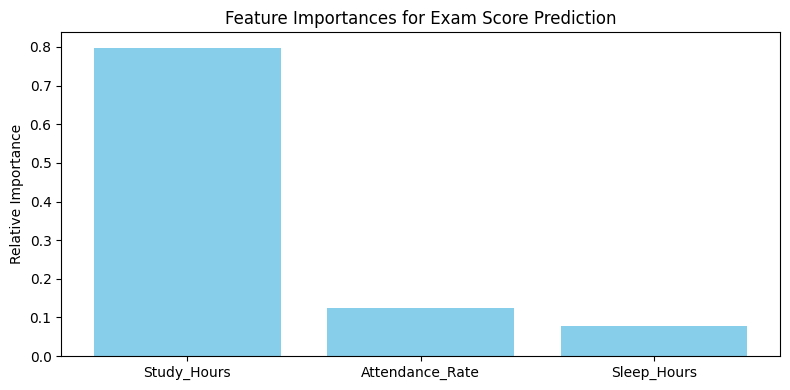

In [28]:
# Let's find inputs that will yield a prediction close to 85
# Study 8.5 hours, 95% attendance, 8 hours of sleep
custom_student = pd.DataFrame([{
    'Study_Hours': 8.5,
    'Attendance_Rate': 95.0,
    'Sleep_Hours': 8.0
}])

predicted_score = rf_model.predict(custom_student)[0]
print(f"Predicting Exam Score for high-performing student:")
print(f"Inputs -> Study: 8.5 hrs, Attendance: 95%, Sleep: 8.0 hrs")
print(f"Predicted Exam Score: {predicted_score:.1f} (Target: 85)")

# Plot feature importances
importances = rf_model.feature_importances_
indices = np.argsort(importances)[::-1]

plt.figure(figsize=(8, 4))
plt.title("Feature Importances for Exam Score Prediction")
plt.bar(range(X.shape[1]), importances[indices], color="skyblue", align="center")
plt.xticks(range(X.shape[1]), [X.columns[i] for i in indices])
plt.ylabel("Relative Importance")
plt.tight_layout()
plt.show()

In [17]:
import pandas as pd
df = pd.read_csv('student_performance_messy.csv')
df

,Study_Hours,Attendance_Rate,Sleep_Hours,Exam_Score
0,4.370861,82.1%,5.412495,78.143056
1,9.556429,54.2%,8.610212,95.633919
2,7.587945,58.1%,7.021009,89.460245
3,6.387926,94.9%,8.305830,92.014766
4,2.404168,80.3%,6.280198,69.683182
...,...,...,...,...
195,4.142886,96.5%,6.895847,89.360395
196,7.533601,92.9%,7.670231,100.000000
197,9.073992,71.4,5.689279,100.000000
198,8.983778,87.5,5.769156,100.000000


In [18]:
df.head()

,Study_Hours,Attendance_Rate,Sleep_Hours,Exam_Score
0,4.370861,82.1%,5.412495,78.143056
1,9.556429,54.2%,8.610212,95.633919
2,7.587945,58.1%,7.021009,89.460245
3,6.387926,94.9%,8.305830,92.014766
4,2.404168,80.3%,6.280198,69.683182


In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Study_Hours      190 non-null    float64
 1   Attendance_Rate  200 non-null    object 
 2   Sleep_Hours      200 non-null    float64
 3   Exam_Score       200 non-null    float64
dtypes: float64(3), object(1)
memory usage: 6.4+ KB


In [20]:
df.isnull().sum().sum()

np.int64(10)

In [21]:
df.duplicated().sum()

np.int64(0)

In [22]:
df.loc[[6, 25, 28, 107]]

,Study_Hours,Attendance_Rate,Sleep_Hours,Exam_Score
6,1.522753,55.1%,6.556807,71.066253
25,8.066584,62.2%,7.198116,99.195084
28,6.331731,94.6%,6.403660,86.525649
107,7.799960,66.1%,8.290149,100.000000


In [29]:
df = df.drop_duplicates()
# Using the actual column names present in the DataFrame
cols = ["Study_Hours", "Attendance_Rate", "Sleep_Hours"]
df[cols] = df[cols].replace({"hrs": "", "%": "", "/ 100": "", "eighty": "88"}, regex=True).astype(float)
df.head()

,Study_Hours,Attendance_Rate,Sleep_Hours,Exam_Score
0,4.370861,82.1,5.412495,78.143056
1,9.556429,54.2,8.610212,95.633919
2,7.587945,58.1,7.021009,89.460245
3,6.387926,94.9,8.305830,92.014766
4,2.404168,80.3,6.280198,69.683182


In [33]:
limits = {"Study_Hours": 24, "Attendance_Rate": 100}

for col, top in limits.items():
    df.loc[df[col] > top, col] = None

df.loc[df["Sleep_Hours"] < 8, "Sleep_Hours"] = None
df = df[df["Exam_Score"] <= 100]
df.head()

,Study_Hours,Attendance_Rate,Sleep_Hours,Exam_Score
0,4.370861,82.1,NaN,78.143056
1,9.556429,54.2,8.610212,95.633919
2,7.587945,58.1,NaN,89.460245
3,6.387926,94.9,8.305830,92.014766
4,2.404168,80.3,NaN,69.683182


In [34]:
len(df)

200

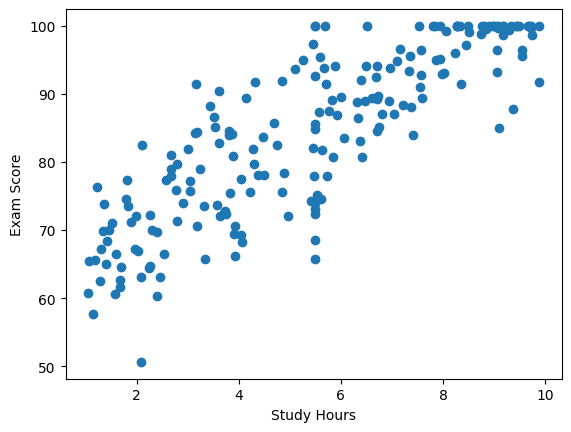

In [35]:
import matplotlib.pyplot as plt

plt.scatter(df["Study_Hours"], df["Exam_Score"])
plt.xlabel("Study Hours")
plt.ylabel("Exam Score")
plt.show()
#

In [38]:
from sklearn.model_selection import train_test_split

# Correcting the missing quote, casing, and column names to match the cleaned DataFrame
X = df[["Study_Hours", "Attendance_Rate", "Sleep_Hours"]]
y = df["Exam_Score"]
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
#

In [40]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import mean_absolute_error

# Instantiate the Random Forest Regressor model
rf_model = RandomForestRegressor(n_estimators=100, random_state=42)

# Fit the model using the training datasets
rf_model.fit(X_train, y_train)

# Make predictions on the test set
y_pred = rf_model.predict(X_test)

# Evaluate the model using Mean Absolute Error
mae = mean_absolute_error(y_test, y_pred)
print(f"Random Forest Regressor trained successfully!")
print(f"Mean Absolute Error on Test Set: {mae:.4f}")

Random Forest Regressor trained successfully!
Mean Absolute Error on Test Set: 4.4412


=== Model Performance Comparison ===


,Metric,Random Forest (Imputed),Linear Regression
0,Mean Absolute Error (MAE),4.5306,3.7427
1,R-squared (R2) Score,0.7510,0.8183


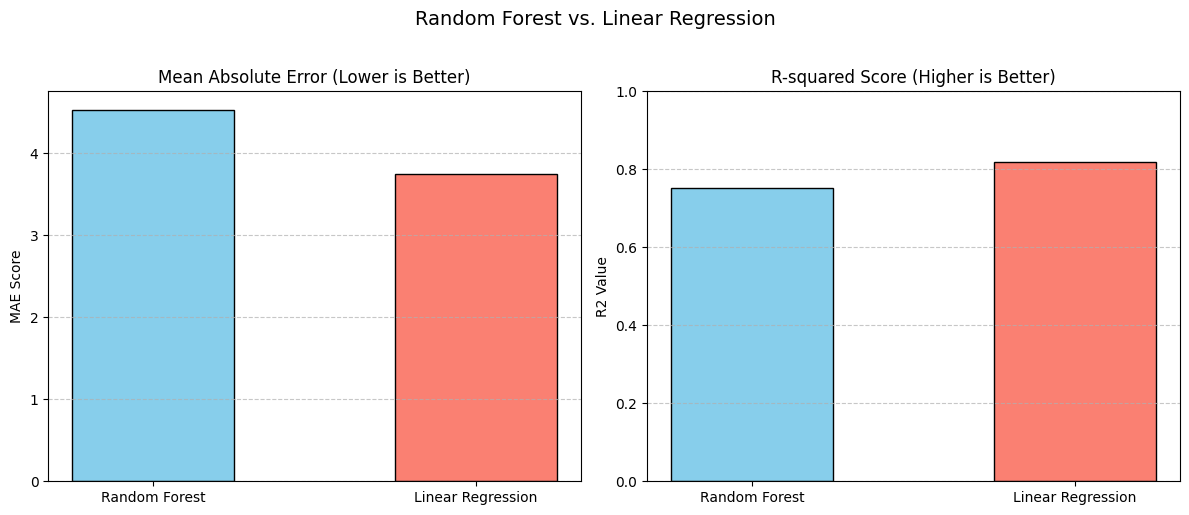

In [47]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, r2_score
from sklearn.impute import SimpleImputer
import pandas as pd
import matplotlib.pyplot as plt

# 1. Impute the NaN values in X_train and X_test using the median of X_train
imputer = SimpleImputer(strategy='median')
X_train_imputed = imputer.fit_transform(X_train)
X_test_imputed = imputer.transform(X_test)

# 2. Retrain the Random Forest on imputed data to keep comparison fair
rf_model_imp = RandomForestRegressor(n_estimators=100, random_state=42)
rf_model_imp.fit(X_train_imputed, y_train)
y_pred_rf = rf_model_imp.predict(X_test_imputed)
mae_rf = mean_absolute_error(y_test, y_pred_rf)
r2_rf = r2_score(y_test, y_pred_rf)

# 3. Train the Linear Regression Model on imputed data
lr_model = LinearRegression()
lr_model.fit(X_train_imputed, y_train)

# 4. Predict on the Test Set
y_pred_lr = lr_model.predict(X_test_imputed)

# 5. Calculate Metrics for Linear Regression
mae_lr = mean_absolute_error(y_test, y_pred_lr)
r2_lr = r2_score(y_test, y_pred_lr)

# 6. Create Comparison DataFrame
comparison_df = pd.DataFrame({
    'Metric': ['Mean Absolute Error (MAE)', 'R-squared (R2) Score'],
    'Random Forest (Imputed)': [mae_rf, r2_rf],
    'Linear Regression': [mae_lr, r2_lr]
})

print("=== Model Performance Comparison ===")
display(comparison_df.round(4))

# 7. Plot Comparison
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Plot MAE (Lower is better)
axes[0].bar(['Random Forest', 'Linear Regression'], [mae_rf, mae_lr], color=['skyblue', 'salmon'], edgecolor='black', width=0.5)
axes[0].set_title('Mean Absolute Error (Lower is Better)', fontsize=12)
axes[0].set_ylabel('MAE Score')
axes[0].grid(axis='y', linestyle='--', alpha=0.7)

# Plot R2 (Higher is better)
axes[1].bar(['Random Forest', 'Linear Regression'], [r2_rf, r2_lr], color=['skyblue', 'salmon'], edgecolor='black', width=0.5)
axes[1].set_title('R-squared Score (Higher is Better)', fontsize=12)
axes[1].set_ylabel('R2 Value')
axes[1].set_ylim(0, 1.0)
axes[1].grid(axis='y', linestyle='--', alpha=0.7)

plt.suptitle('Random Forest vs. Linear Regression', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

=== Linear Regression Coefficients ===


,Feature,Coefficient
0,Study_Hours,3.996754
1,Attendance_Rate,0.221262
2,Sleep_Hours,-3.532462


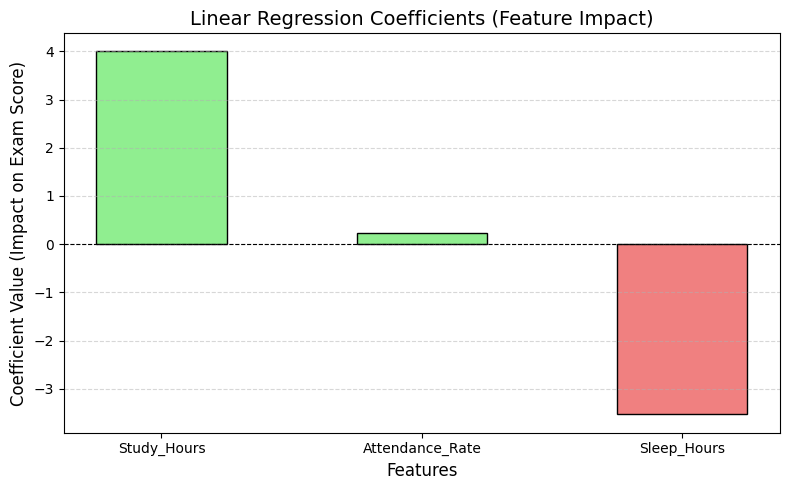

In [48]:
import pandas as pd
import matplotlib.pyplot as plt

# Retrieve the coefficients from our trained linear regression model
coefficients = lr_model.coef_
features = X_train.columns

# Create a DataFrame for nice formatting
coef_df = pd.DataFrame({
    'Feature': features,
    'Coefficient': coefficients
}).sort_values(by='Coefficient', ascending=False).reset_index(drop=True)

print("=== Linear Regression Coefficients ===")
display(coef_df)

# Plot the coefficients
plt.figure(figsize=(8, 5))
colors = ['lightgreen' if c >= 0 else 'lightcoral' for c in coef_df['Coefficient']]
plt.bar(coef_df['Feature'], coef_df['Coefficient'], color=colors, edgecolor='black', width=0.5)
plt.axhline(0, color='black', linewidth=0.8, linestyle='--')
plt.title('Linear Regression Coefficients (Feature Impact)', fontsize=14)
plt.xlabel('Features', fontsize=12)
plt.ylabel('Coefficient Value (Impact on Exam Score)', fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

=== Correlation Matrix (On Training Data with NaNs) ===


,Study_Hours,Attendance_Rate,Sleep_Hours,Exam_Score
Study_Hours,1.0000,-0.0046,0.0396,0.8415
Attendance_Rate,-0.0046,1.0000,0.0717,0.2607
Sleep_Hours,0.0396,0.0717,1.0000,-0.0040
Exam_Score,0.8415,0.2607,-0.0040,1.0000



=== Correlation Matrix (On Imputed Training Data) ===


,Study_Hours,Attendance_Rate,Sleep_Hours,Exam_Score
Study_Hours,1.0000,-0.0046,0.0267,0.8415
Attendance_Rate,-0.0046,1.0000,0.0524,0.2607
Sleep_Hours,0.0267,0.0524,1.0000,-0.0116
Exam_Score,0.8415,0.2607,-0.0116,1.0000


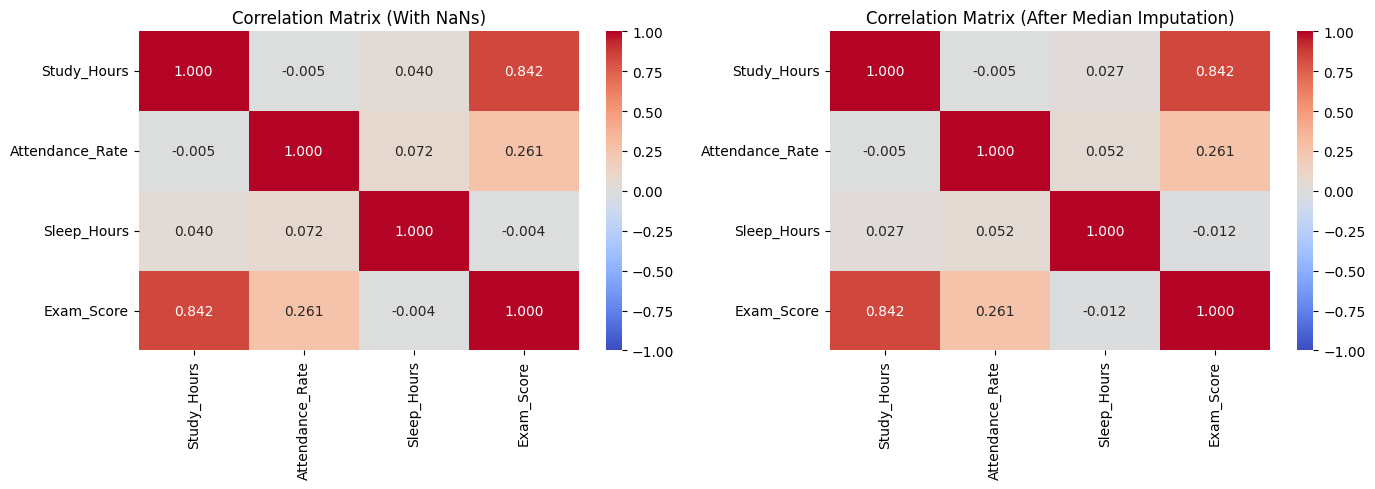

In [49]:
import seaborn as sns
import matplotlib.pyplot as plt

# 1. We will use the original non-imputed X_train with the target y_train to see
# how our manual preprocessing/filtering affected correlation patterns.
temp_df = X_train.copy()
temp_df['Exam_Score'] = y_train

# Calculate correlation matrix
corr_matrix = temp_df.corr()
print("=== Correlation Matrix (On Training Data with NaNs) ===")
display(corr_matrix.round(4))

# 2. Let's do the same on the IMPUTED training data to see exactly what the Linear Regression model saw.
X_train_imp_df = pd.DataFrame(X_train_imputed, columns=X_train.columns)
X_train_imp_df['Exam_Score'] = y_train.values

corr_matrix_imputed = X_train_imp_df.corr()
print("\n=== Correlation Matrix (On Imputed Training Data) ===")
display(corr_matrix_imputed.round(4))

# Plotting side-by-side heatmaps to visual the impact of imputation
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.heatmap(corr_matrix, annot=True, cmap='coolwarm', fmt='.3f', ax=axes[0], vmin=-1, vmax=1)
axes[0].set_title('Correlation Matrix (With NaNs)')

sns.heatmap(corr_matrix_imputed, annot=True, cmap='coolwarm', fmt='.3f', ax=axes[1], vmin=-1, vmax=1)
axes[1].set_title('Correlation Matrix (After Median Imputation)')

plt.tight_layout()
plt.show()

In [43]:
from sklearn.metrics import r2_score

# Calculate the R-squared score
r2 = r2_score(y_test, y_pred)

print("=== Model Performance Evaluation ===")
print(f"Mean Absolute Error (MAE): {mae:.4f}")
print(f"R-squared (R2) Score:     {r2:.4f}")
print(f"This means our model explains {r2 * 100:.2f}% of the variance in exam scores.")

=== Model Performance Evaluation ===
Mean Absolute Error (MAE): 4.4412
R-squared (R2) Score:     0.7655
This means our model explains 76.55% of the variance in exam scores.


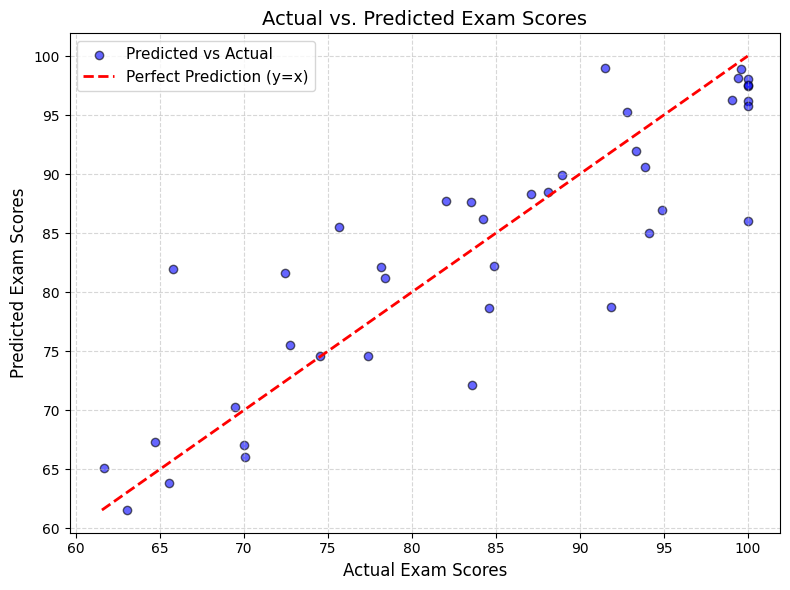

In [44]:
import matplotlib.pyplot as plt
import numpy as np

# Create the plot
plt.figure(figsize=(8, 6))
plt.scatter(y_test, y_pred, color='blue', alpha=0.6, edgecolors='k', label='Predicted vs Actual')

# Add a diagonal line for reference (where predicted equals actual)
perfect_line = np.linspace(min(y_test.min(), y_pred.min()), max(y_test.max(), y_pred.max()), 100)
plt.plot(perfect_line, perfect_line, color='red', linestyle='--', linewidth=2, label='Perfect Prediction (y=x)')

# Formatting the plot
plt.title('Actual vs. Predicted Exam Scores', fontsize=14)
plt.xlabel('Actual Exam Scores', fontsize=12)
plt.ylabel('Predicted Exam Scores', fontsize=12)
plt.legend(fontsize=11)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

In [42]:
# Define the habits for the new student
new_student_data = {
    'Study_Hours': 6.5,       # Number of hours studied
    'Attendance_Rate': 88.0,   # Attendance percentage (0 - 100)
    'Sleep_Hours': 7.5         # Average hours of sleep
}

# Convert to DataFrame to match the model's feature structure
new_student_df = pd.DataFrame([new_student_data])

# Use the trained Random Forest model to predict the score
predicted_score = rf_model.predict(new_student_df)[0]

# Print the results
print("=== Exam Score Prediction ===")
for feature, value in new_student_data.items():
    print(f"{feature.replace('_', ' ')}: {value}")
print(f"-----------------------------")
print(f"Predicted Exam Score: {predicted_score:.2f} / 100")

=== Exam Score Prediction ===
Study Hours: 6.5
Attendance Rate: 88.0
Sleep Hours: 7.5
-----------------------------
Predicted Exam Score: 96.41 / 100


In [50]:
# Define custom habits for the new student
custom_study_hours = 7.5
custom_attendance_rate = 90.0
custom_sleep_hours = 8.2

# Prepare the input for both models. Note: Linear regression expects imputed shape
new_student_raw = pd.DataFrame([{
    'Study_Hours': custom_study_hours,
    'Attendance_Rate': custom_attendance_rate,
    'Sleep_Hours': custom_sleep_hours
}])

# Impute in case any value is missing (to remain robust)
new_student_imputed = imputer.transform(new_student_raw)

# Predict using both models
rf_predicted_score = rf_model_imp.predict(new_student_imputed)[0]
lr_predicted_score = lr_model.predict(new_student_imputed)[0]

# Print the results
print("=== Exam Score Prediction for New Student ===")
print(f"Study Hours:     {custom_study_hours} hrs")
print(f"Attendance Rate: {custom_attendance_rate}%")
print(f"Sleep Hours:     {custom_sleep_hours} hrs")
print("----------------------------------------------")
print(f"Random Forest Regressor Predicted Score: {rf_predicted_score:.2f} / 100")
print(f"Linear Regression Predicted Score:      {lr_predicted_score:.2f} / 100")

=== Exam Score Prediction for New Student ===
Study Hours:     7.5 hrs
Attendance Rate: 90.0%
Sleep Hours:     8.2 hrs
----------------------------------------------
Random Forest Regressor Predicted Score: 97.11 / 100
Linear Regression Predicted Score:      97.15 / 100


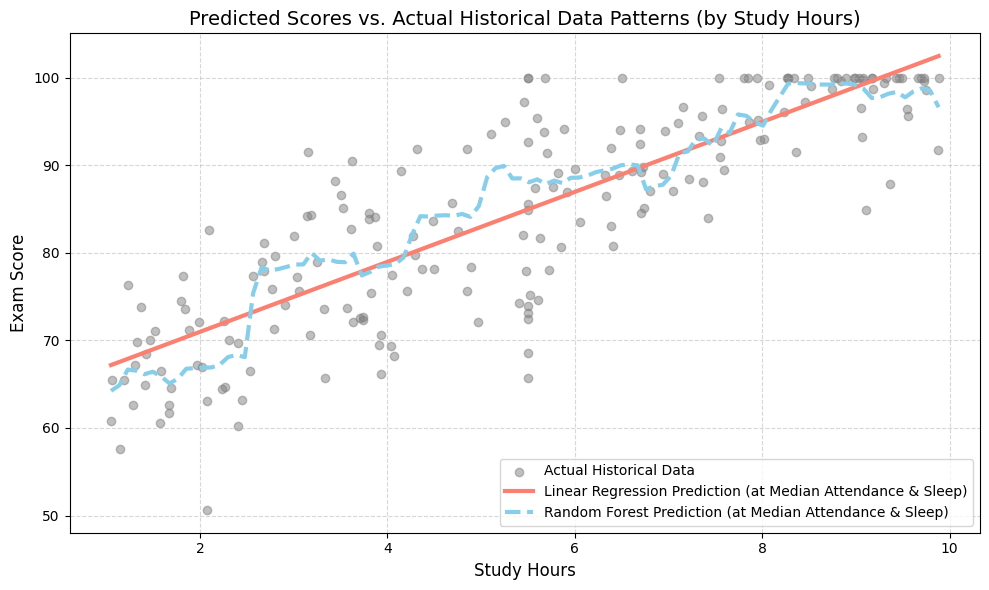

In [51]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

# Prepare grid values for Study Hours to map the model prediction line
study_hours_grid = np.linspace(X['Study_Hours'].min(), X['Study_Hours'].max(), 100)

# To isolate the effect of Study Hours, we keep other features constant at their median values
median_attendance = X['Attendance_Rate'].median()
median_sleep = X_train_imp_df['Sleep_Hours'].median() # using imputed median to keep it continuous

grid_data = pd.DataFrame({
    'Study_Hours': study_hours_grid,
    'Attendance_Rate': [median_attendance] * 100,
    'Sleep_Hours': [median_sleep] * 100
})

# Impute to match input shape expectations
grid_data_imputed = imputer.transform(grid_data)

# Predict using both models over the grid
y_grid_rf = rf_model_imp.predict(grid_data_imputed)
y_grid_lr = lr_model.predict(grid_data_imputed)

# Plotting
plt.figure(figsize=(10, 6))

# Scatter actual test points (or entire dataset) to see historical patterns
plt.scatter(df['Study_Hours'], df['Exam_Score'], color='gray', alpha=0.5, label='Actual Historical Data')

# Plot models' decision boundaries/lines
plt.plot(study_hours_grid, y_grid_lr, color='salmon', linewidth=3, label=f'Linear Regression Prediction (at Median Attendance & Sleep)')
plt.plot(study_hours_grid, y_grid_rf, color='skyblue', linewidth=3, linestyle='--', label=f'Random Forest Prediction (at Median Attendance & Sleep)')

plt.title('Predicted Scores vs. Actual Historical Data Patterns (by Study Hours)', fontsize=14)
plt.xlabel('Study Hours', fontsize=12)
plt.ylabel('Exam Score', fontsize=12)
plt.legend(fontsize=10)
plt.grid(True, linestyle='--', alpha=0.5)
plt.tight_layout()
plt.show()

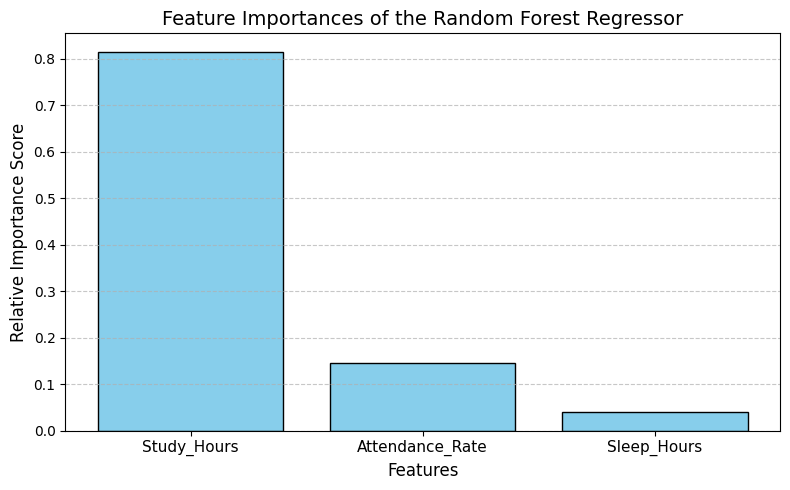

In [41]:
import matplotlib.pyplot as plt
import pandas as pd
import numpy as np

# Get feature importances from the trained Random Forest model
importances = rf_model.feature_importances_
feature_names = X_train.columns

# Sort importances in descending order
indices = np.argsort(importances)[::-1]

# Plot the feature importances
plt.figure(figsize=(8, 5))
plt.title("Feature Importances of the Random Forest Regressor", fontsize=14)
plt.bar(range(X_train.shape[1]), importances[indices], color="skyblue", align="center", edgecolor='black')
plt.xticks(range(X_train.shape[1]), [feature_names[i] for i in indices], fontsize=11)
plt.xlabel("Features", fontsize=12)
plt.ylabel("Relative Importance Score", fontsize=12)
plt.grid(axis='y', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()

=== Feature Importances ===


,Feature,Relative_Importance
0,Study_Hours,0.813748
1,Attendance_Rate,0.145919
2,Sleep_Hours,0.040333


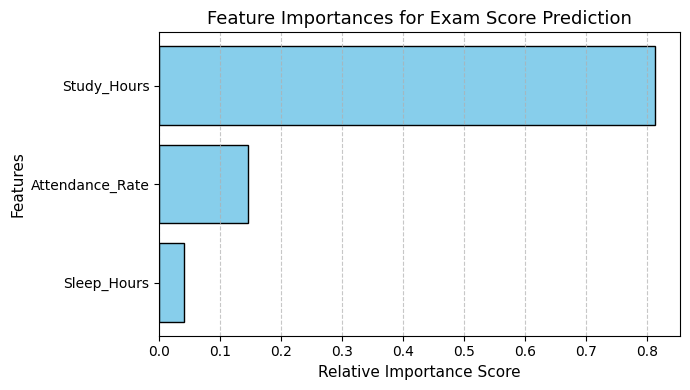

In [45]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Retrieve feature importances from the trained model
importances = rf_model.feature_importances_
feature_names = X_train.columns

# Create a DataFrame for nice formatting
importance_df = pd.DataFrame({
    'Feature': feature_names,
    'Relative_Importance': importances
}).sort_values(by='Relative_Importance', ascending=False).reset_index(drop=True)

# Display the structured numeric values
print("=== Feature Importances ===")
display(importance_df)

# Plot the feature importances
plt.figure(figsize=(7, 4))
plt.barh(importance_df['Feature'][::-1], importance_df['Relative_Importance'][::-1], color='skyblue', edgecolor='black')
plt.title('Feature Importances for Exam Score Prediction', fontsize=13)
plt.xlabel('Relative Importance Score', fontsize=11)
plt.ylabel('Features', fontsize=11)
plt.grid(axis='x', linestyle='--', alpha=0.7)
plt.tight_layout()
plt.show()